
---
# <center style="color: orange; font-weight: bold; font-size: 2rem;">Fonctions BLAS en python </center>
---

- Importation des bibliothèques

In [ ]:
import ctypes
import numpy as np
import time 

# Charger la bibliothèque MKL
mkl = ctypes.CDLL("libmkl_rt.so")  


- Constantes CBLAS

In [27]:
CBLAS_ROW_MAJOR = 101
CBLAS_NO_TRANS = 111

In [29]:
#cblas_ddot - Produit scalaire 

# Définir la signature de cblas_ddot

mkl.cblas_ddot.argtypes = [ctypes.c_int, ctypes.POINTER(ctypes.c_double), ctypes.c_int,
                           ctypes.POINTER(ctypes.c_double), ctypes.c_int]
mkl.cblas_ddot.restype = ctypes.c_double
 
t1 = time.time()

def blas_ddot(x, y):
    """Calcule le produit scalaire de deux vecteurs x et y."""
    n = len(x)
    assert len(y) == n, "Les vecteurs doivent avoir la même longueur"
    return mkl.cblas_ddot(n, x.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 1,
                          y.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 1)
    

# Données
x = np.array([1.0, 2.0, 3.0,8], dtype=np.float64)
y = np.array([4.0, 5.0, 6.0,-9], dtype=np.float64)

# Appel
result = blas_ddot(x, y)
print(f"Produit scalaire de {x} et {y} : {result}")  # Résultat : 32.0 (1×4 + 2×5 + 3×6)

Produit scalaire de [1. 2. 3. 8.] et [ 4.  5.  6. -9.] : -40.0


In [ ]:
# Sans 
# Définition des vecteurs
v1 = np.array([1, 2, 3])
v2 = np.array([4, 5, 6])

# Calcul du produit scalaire
produit_scalaire = np.dot(v1, v2)

print("Produit scalaire :", produit_scalaire)


In [17]:
#cblas_dgemv - Multiplication matrice-vecteur
# Définir la signature de cblas_dgemv
mkl.cblas_dgemv.argtypes = [ctypes.c_int, ctypes.c_int, ctypes.c_int, ctypes.c_int,
                            ctypes.c_double, ctypes.POINTER(ctypes.c_double), ctypes.c_int,
                            ctypes.POINTER(ctypes.c_double), ctypes.c_int, ctypes.c_double,
                            ctypes.POINTER(ctypes.c_double), ctypes.c_int]
mkl.cblas_dgemv.restype = None

def blas_dgemv(a, x, alpha=1.0, beta=0.0):
    """Calcule y = alpha * A * x + beta * y, renvoie un nouveau vecteur y."""
    m, n = a.shape
    assert x.shape[0] == n, "Dimensions incompatibles entre A et x"
    y = np.zeros(m, dtype=np.float64)
    mkl.cblas_dgemv(CBLAS_ROW_MAJOR, CBLAS_NO_TRANS, m, n, alpha,
                    a.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), n,
                    x.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 1,
                    beta, y.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 1)
    return y

# Données
a = np.array([[1.0, 2.0], [3.0, 4.0]], dtype=np.float64)
x = np.array([1.0, 1.0], dtype=np.float64)

# Appel
result = blas_dgemv(a, x)
print(f"Résultat de A * x : {result}")  # Résultat : [3.0, 7.0]

Résultat de A * x : [3. 7.]



---
# <center style="color: orange; font-weight: bold; font-size: 2rem;">Fonctions LAPACK en python </center>
---

In [18]:
# Initialisation globale de MKL 
import ctypes
import numpy as np

# Charger la bibliothèque MKL
mkl = ctypes.CDLL("libmkl_rt.so")  # Sous Ubuntu, ajuste si nécessaire

# En Python avec ctypes, nous définissons manuellement les constantes pour spécifier le format des matrices (optionnel pour LAPACK).
# Constantes LAPACKE (si utilisées)
LAPACK_ROW_MAJOR = 101  # Matrice stockée par lignes (comme NumPy)

In [19]:
#   dgesv - Résolution d’un système linéaire
# Définir la signature de dgesv (interface Fortran)
mkl.dgesv.argtypes = [ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_int),
                      ctypes.POINTER(ctypes.c_double), ctypes.POINTER(ctypes.c_int),
                      ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_double),
                      ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_int)]
mkl.dgesv.restype = None

def lapack_dgesv(a, b):
    """Résout le système Ax = b, où A est une matrice carrée et b un vecteur."""
    n = a.shape[0]
    assert a.shape[1] == n, "A doit être carrée"
    assert b.shape[0] == n, "Dimensions incompatibles entre A et b"
    nrhs = 1  # Nombre de colonnes de b (1 pour un vecteur)
    a_copy = np.copy(a)  # Copie car dgesv modifie A
    b_copy = np.copy(b)  # Copie car b devient la solution x
    ipiv = np.zeros(n, dtype=np.int32)  # Tableau des pivots
    info = ctypes.c_int(0)
    mkl.dgesv(ctypes.byref(ctypes.c_int(n)), ctypes.byref(ctypes.c_int(nrhs)),
              a_copy.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), ctypes.byref(ctypes.c_int(n)),
              ipiv.ctypes.data_as(ctypes.POINTER(ctypes.c_int)),
              b_copy.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), ctypes.byref(ctypes.c_int(n)),
              ctypes.byref(info))
    if info.value != 0:
        raise ValueError(f"dgesv a échoué avec info = {info.value}")
    return b_copy  # b_copy contient la solution x


# Données
a = np.array([[4.0, 1.0], [1.0, 3.0]], dtype=np.float64)  # Matrice A
b = np.array([1.0, 2.0], dtype=np.float64)               # Vecteur b

# Appel
x = lapack_dgesv(a, b)
print(f"Solution x du système Ax = b : {x}")  # Résultat ≈ [0.142857, 0.428571]

Solution x du système Ax = b : [0.09090909 0.63636364]


In [20]:
# dgetrf - Factorisation LU
# Définir la signature de dgetrf
mkl.dgetrf.argtypes = [ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_int),
                       ctypes.POINTER(ctypes.c_double), ctypes.POINTER(ctypes.c_int),
                       ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_int)]
mkl.dgetrf.restype = None

def lapack_dgetrf(a):
    """Effectue la factorisation LU de A (A = P L U). Retourne L+U et les pivots."""
    m, n = a.shape
    a_copy = np.copy(a)  # Copie car dgetrf modifie A
    ipiv = np.zeros(min(m, n), dtype=np.int32)  # Tableau des pivots
    info = ctypes.c_int(0)
    mkl.dgetrf(ctypes.byref(ctypes.c_int(m)), ctypes.byref(ctypes.c_int(n)),
               a_copy.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), ctypes.byref(ctypes.c_int(m)),
               ipiv.ctypes.data_as(ctypes.POINTER(ctypes.c_int)), ctypes.byref(info))
    if info.value != 0:
        raise ValueError(f"dgetrf a échoué avec info = {info.value}")
    return a_copy, ipiv  # a_copy contient L+U combinés, ipiv les pivots

# Données
a = np.array([[4.0, 1.0], [1.0, 3.0]], dtype=np.float64)

# Appel
lu, piv = lapack_dgetrf(a)
print(f"Matrice LU :\n{lu}\nPivots : {piv}")
# Résultat : lu ≈ [[4.0, 1.0], [0.25, 2.75]], piv = [1, 2]

Matrice LU :
[[4.   0.25]
 [1.   2.75]]
Pivots : [1 2]


In [21]:
# dgetri - Inversion d’une matrice (après factorisation LU)
# Définir la signature de dgetri
mkl.dgetri.argtypes = [ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_double),
                       ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_int),
                       ctypes.POINTER(ctypes.c_double), ctypes.POINTER(ctypes.c_int),
                       ctypes.POINTER(ctypes.c_int)]
mkl.dgetri.restype = None

def lapack_dgetri(a):
    """Calcule l’inverse de A après factorisation LU. Nécessite dgetrf au préalable."""
    n = a.shape[0]
    assert a.shape[1] == n, "A doit être carrée"
    lu, ipiv = lapack_dgetrf(a)  # Factorisation LU préalable
    a_inv = np.copy(lu)  # Copie car dgetri modifie la matrice
    lwork = n * n  # Taille du tableau de travail
    work = np.zeros(lwork, dtype=np.float64)
    info = ctypes.c_int(0)
    mkl.dgetri(ctypes.byref(ctypes.c_int(n)), a_inv.ctypes.data_as(ctypes.POINTER(ctypes.c_double)),
               ctypes.byref(ctypes.c_int(n)), ipiv.ctypes.data_as(ctypes.POINTER(ctypes.c_int)),
               work.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), ctypes.byref(ctypes.c_int(lwork)),
               ctypes.byref(info))
    if info.value != 0:
        raise ValueError(f"dgetri a échoué avec info = {info.value}")
    return a_inv
# Données
a = np.array([[4.0, 1.0], [1.0, 3.0]], dtype=np.float64)

# Appel
a_inv = lapack_dgetri(a)
print(f"Inverse de A :\n{a_inv}")  # Résultat ≈ [[0.272727, -0.090909], [-0.090909, 0.363636]]


Inverse de A :
[[ 0.27272727 -0.09090909]
 [-0.09090909  0.36363636]]



---
# <center style="color: orange; font-weight: bold; font-size: 2rem;">Modèle épidémiologique SIR et résolution numérique</center>
---

Le modèle **SIR (Susceptible - Infected - Recovered)** est utilisé pour modéliser la propagation d’une épidémie. Il est défini par le système d’équations différentielles suivantes :

$
\frac{dS}{dt} = -\beta S I
$

$
\frac{dI}{dt} = \beta S I - \gamma I
$

$
\frac{dR}{dt} = \gamma I
$

où :
- \( S(t) \) : Nombre d’individus susceptibles,
- \( I(t) \) : Nombre d’individus infectés,
- \( R(t) \) : Nombre d’individus guéris,
- \( $\beta $\) : Taux de transmission,
- \( $\gamma$ \) : Taux de récupération.

Euler explicite calcule chaque pas temporel avec : y^n+1=yn+Δt⋅f(yn)yn+1=yn+Δt⋅f(yn), où y=[S,I,R]y=[S,I,R] et ff est le modèle SIR.
BLAS intervient pour effectuer cette mise à jour vectorielle de manière optimisée.

Temps d'exécution avec MKL:  0.05425143241882324


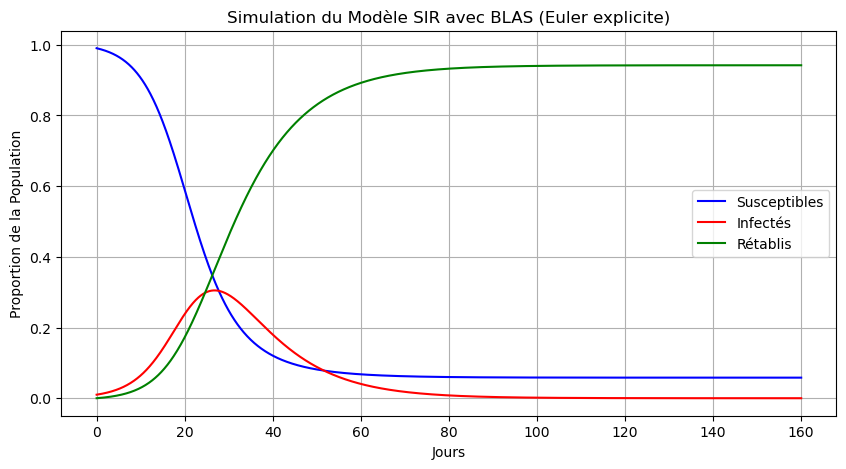

In [36]:
import ctypes
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# Initialisation de MKL
mkl = ctypes.CDLL("libmkl_rt.so")  # Sous Ubuntu, ajuste si nécessaire


# Définir la signature de cblas_daxpy
mkl.cblas_daxpy.argtypes = [ctypes.c_int, ctypes.c_double, ctypes.POINTER(ctypes.c_double),
                            ctypes.c_int, ctypes.POINTER(ctypes.c_double), ctypes.c_int]
mkl.cblas_daxpy.restype = None

def blas_daxpy(x, y, alpha=1.0):
    """Met à jour y avec y = alpha * x + y."""
    n = len(x)
    assert len(y) == n, "Les vecteurs doivent avoir la même longueur"
    mkl.cblas_daxpy(n, alpha, x.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 1,
                    y.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 1)
    return y

# Définition du modèle SIR
def sir_model(y, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return np.array([dSdt, dIdt, dRdt], dtype=np.float64)

# Paramètres du modèle
beta = 0.3   # Taux d'infection
gamma = 0.1  # Taux de guérison

# Conditions initiales
S0 = 0.99  # 99% de la population est susceptible
I0 = 0.01  # 1% de la population est infectée
R0 = 0.0   # Aucun rétabli au début
y0 = np.array([S0, I0, R0], dtype=np.float64)

# Période de simulation
t_span = (0, 160)  # Simulation sur 160 jours
dt = 0.1  # Pas de temps (choisi petit pour stabilité Euler explicite)
t_eval = np.arange(t_span[0], t_span[1] + dt, dt)
Nt = len(t_eval)

# Tableaux pour stocker les résultats
S = np.zeros(Nt)
I = np.zeros(Nt)
R = np.zeros(Nt)
S[0], I[0], R[0] = S0, I0, R0
y = np.copy(y0)

t1 = time.time()

# Simulation avec Euler explicite et BLAS
for n in range(Nt - 1):
    dydt = sir_model(y, beta, gamma)  # Calcul des dérivées
    y = blas_daxpy(dydt, y, alpha=dt)  # Mise à jour : y^{n+1} = y^n + dt * dydt
    S[n + 1], I[n + 1], R[n + 1] = y  # Stockage des résultats


print("Temps d'exécution avec MKL: ", time.time() - t1)

# Tracé des courbes
plt.figure(figsize=(10, 5))
plt.plot(t_eval, S, label="Susceptibles", color='blue')
plt.plot(t_eval, I, label="Infectés", color='red')
plt.plot(t_eval, R, label="Rétablis", color='green')
plt.xlabel("Jours")
plt.ylabel("Proportion de la Population")
plt.title("Simulation du Modèle SIR avec BLAS (Euler explicite)")
plt.legend()
plt.grid()
plt.show()

## sans MKL

Temps d'exécution sans MKL:  0.006430149078369141


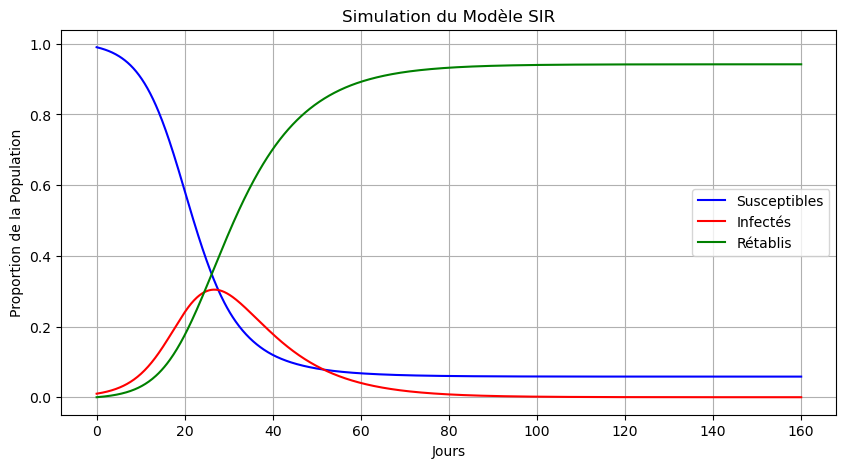

In [34]:
t2 = time.time()

# Définition du modèle SIR
def sir_model(t, y, beta, gamma):
    S, I, R = y  # Extraction des variables
    dSdt = -beta * S * I  # Variation des susceptibles
    dIdt = beta * S * I - gamma * I  # Variation des infectés
    dRdt = gamma * I  # Variation des rétablis
    return [dSdt, dIdt, dRdt]

# Paramètres du modèle
beta = 0.3   # Taux d'infection
gamma = 0.1  # Taux de guérison

# Conditions initiales
S0 = 0.99  # 99% de la population est susceptible
I0 = 0.01  # 1% de la population est infectée
R0 = 0.0   # Aucun rétabli au début

# Période de simulation
t_span = (0, 160)  # Simulation sur 160 jours
t_eval = np.linspace(t_span[0], t_span[1], 1000)  # Points de temps pour l'évaluation


# Résolution numérique des équations
solution = solve_ivp(
    sir_model, t_span, [S0, I0, R0], args=(beta, gamma), t_eval=t_eval
)

# Extraction des résultats
S, I, R = solution.y

print("Temps d'exécution sans MKL: ", time.time() - t2)

# Tracé des courbes
plt.figure(figsize=(10, 5))
plt.plot(solution.t, S, label="Susceptibles", color='blue')
plt.plot(solution.t, I, label="Infectés", color='red')
plt.plot(solution.t, R, label="Rétablis", color='green')
plt.xlabel("Jours")
plt.ylabel("Proportion de la Population")
plt.title("Simulation du Modèle SIR")
plt.legend()
plt.grid()
plt.show()